# Final comparison

In [1]:
import sys, json
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from src.config import SEED
from src.data import load_splits
from src.metrics import evaluate, bootstrap_ci, bootstrap_diff
from src.models import WeightedXGB
from src.softmax import SoftmaxRegression

sns.set_theme(style='whitegrid')

data, y_train, y_test = load_splits()
best_params = json.loads(Path('../results/xgb_best_params.json').read_text())
best_params

{'colsample_bytree': 0.6298202574719083,
 'learning_rate': 0.28953368345102004,
 'max_depth': 10,
 'n_estimators': 228,
 'subsample': 0.679486272613669}

## Fit every model on both feature sets

Logistic regressions and the softmax use the scaled features, trees use the raw ones. The softmax runs 1,500 iterations (the loss is flat well before).

In [2]:
MODELS = ['LogReg', 'LogReg balanced', 'LogReg + undersampling', 'LogReg + SMOTE',
          'Softmax scratch (balanced)', 'Balanced RF', 'RF balanced',
          'XGBoost unweighted', 'XGBoost weighted', 'XGBoost tuned']

def fit_predict(name, d):
    Xs_tr, Xs_te, X_tr, X_te = d['X_train_s'], d['X_test_s'], d['X_train'], d['X_test']
    if name.startswith('LogReg'):
        X, y = Xs_tr, y_train
        if name == 'LogReg + undersampling':
            X, y = RandomUnderSampler(random_state=SEED).fit_resample(X, y)
        if name == 'LogReg + SMOTE':
            X, y = SMOTE(k_neighbors=5, random_state=SEED).fit_resample(X, y)
        cw = 'balanced' if name == 'LogReg balanced' else None
        return LogisticRegression(max_iter=5000, class_weight=cw, random_state=SEED).fit(X, y).predict(Xs_te)
    if name == 'Softmax scratch (balanced)':
        return SoftmaxRegression(learning_rate=0.5, n_iter=1500, l2=1e-3, class_weight='balanced').fit(Xs_tr, y_train).predict(Xs_te)
    if name == 'Balanced RF':
        m = BalancedRandomForestClassifier(n_estimators=100, sampling_strategy='all', replacement=True,
                                           bootstrap=False, random_state=SEED, n_jobs=-1)
    elif name == 'RF balanced':
        m = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=-1)
    elif name == 'XGBoost unweighted':
        m = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1)
        return m.fit(X_tr, y_train - 1).predict(X_te) + 1
    elif name == 'XGBoost weighted':
        m = WeightedXGB(n_jobs=-1)
    else:
        m = WeightedXGB(**best_params, n_jobs=-1)
    return m.fit(X_tr, y_train).predict(X_te)

preds = {(fs, name): fit_predict(name, d) for fs, d in data.items() for name in MODELS}
len(preds)

/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Predicti

20

## Results with 95 % bootstrap intervals

The test rows are resampled 1,000 times (the same resamples for every model). Class 1 has only 80 test rows, so its recall has a wide interval.

In [3]:
rows = []
for (fs, name), pred in preds.items():
    ci = bootstrap_ci(y_test, pred)
    _, table = evaluate(y_test, pred)
    row = {'features': fs, 'model': name,
           'precision_1': table.loc[1, 'precision'], 'precision_2': table.loc[2, 'precision']}
    for m in ['macro_f1', 'accuracy', 'recall_1', 'recall_2']:
        row[m], row[m + '_low'], row[m + '_high'] = ci.loc[m, ['value', 'low', 'high']]
    rows.append(row)
results = pd.DataFrame(rows)

def fmt(r, m):
    return f"{r[m]:.3f} [{r[m + '_low']:.3f}, {r[m + '_high']:.3f}]"

show = results[['features', 'model']].copy()
for m in ['macro_f1', 'accuracy', 'recall_1', 'recall_2']:
    show[m] = results.apply(lambda r: fmt(r, m), axis=1)
show.set_index(['features', 'model'])

macro_f1  \
features  model                                              
salary    LogReg                      0.215 [0.210, 0.220]   
          LogReg balanced             0.190 [0.184, 0.196]   
          LogReg + undersampling      0.205 [0.199, 0.211]   
          LogReg + SMOTE              0.190 [0.183, 0.196]   
          Softmax scratch (balanced)  0.189 [0.184, 0.196]   
          Balanced RF                 0.467 [0.460, 0.475]   
          RF balanced                 0.606 [0.592, 0.623]   
          XGBoost unweighted          0.933 [0.914, 0.950]   
          XGBoost weighted            0.909 [0.890, 0.924]   
          XGBoost tuned               0.926 [0.907, 0.943]   
no_salary LogReg                      0.195 [0.190, 0.200]   
          LogReg balanced             0.146 [0.140, 0.152]   
          LogReg + undersampling      0.168 [0.163, 0.174]   
          LogReg + SMOTE              0.147 [0.141, 0.153]   
          Softmax scratch (balanced)  0.146 [0.140, 0.152]   
          Balanced RF                 0.183 [0.177, 0.188]   
          RF balanced                 0.192 [0.187, 0.197]   
          XGBoost unweighted          0.192 [0.187, 0.197]   
          XGBoost weighted            0.189 [0.182, 0.195]   
          XGBoost tuned               0.192 [0.186, 0.197]   

                                                  accuracy  \
features  model                                              
salary    LogReg                      0.378 [0.370, 0.387]   
          LogReg balanced             0.261 [0.253, 0.267]   
          LogReg + undersampling      0.269 [0.261, 0.277]   
          LogReg + SMOTE              0.260 [0.252, 0.267]   
          Softmax scratch (balanced)  0.260 [0.252, 0.267]   
          Balanced RF                 0.581 [0.573, 0.590]   
          RF balanced                 0.792 [0.785, 0.799]   
          XGBoost unweighted          0.988 [0.987, 0.990]   
          XGBoost weighted            0.979 [0.976, 0.981]   
          XGBoost tuned               0.987 [0.985, 0.989]   
no_salary LogReg                      0.314 [0.307, 0.322]   
          LogReg balanced             0.161 [0.155, 0.167]   
          LogReg + undersampling      0.205 [0.198, 0.212]   
          LogReg + SMOTE              0.158 [0.152, 0.165]   
          Softmax scratch (balanced)  0.161 [0.155, 0.167]   
          Balanced RF                 0.235 [0.229, 0.243]   
          RF balanced                 0.309 [0.301, 0.317]   
          XGBoost unweighted          0.310 [0.302, 0.318]   
          XGBoost weighted            0.247 [0.239, 0.255]   
          XGBoost tuned               0.303 [0.295, 0.311]   

                                                  recall_1  \
features  model                                              
salary    LogReg                      0.000 [0.000, 0.000]   
          LogReg balanced             0.475 [0.362, 0.583]   
          LogReg + undersampling      0.475 [0.368, 0.575]   
          LogReg + SMOTE              0.512 [0.404, 0.627]   
          Softmax scratch (balanced)  0.475 [0.362, 0.583]   
          Balanced RF                 0.338 [0.244, 0.438]   
          RF balanced                 0.025 [0.000, 0.068]   
          XGBoost unweighted          0.637 [0.528, 0.747]   
          XGBoost weighted            0.800 [0.707, 0.886]   
          XGBoost tuned               0.637 [0.528, 0.747]   
no_salary LogReg                      0.000 [0.000, 0.000]   
          LogReg balanced             0.463 [0.356, 0.571]   
          LogReg + undersampling      0.212 [0.125, 0.306]   
          LogReg + SMOTE              0.438 [0.333, 0.542]   
          Softmax scratch (balanced)  0.463 [0.356, 0.571]   
          Balanced RF                 0.050 [0.012, 0.103]   
          RF balanced                 0.000 [0.000, 0.000]   
          XGBoost unweighted          0.000 [0.000, 0.000]   
          XGBoost weighted            0.062 [0.013, 0.118]   
          XGBoost 

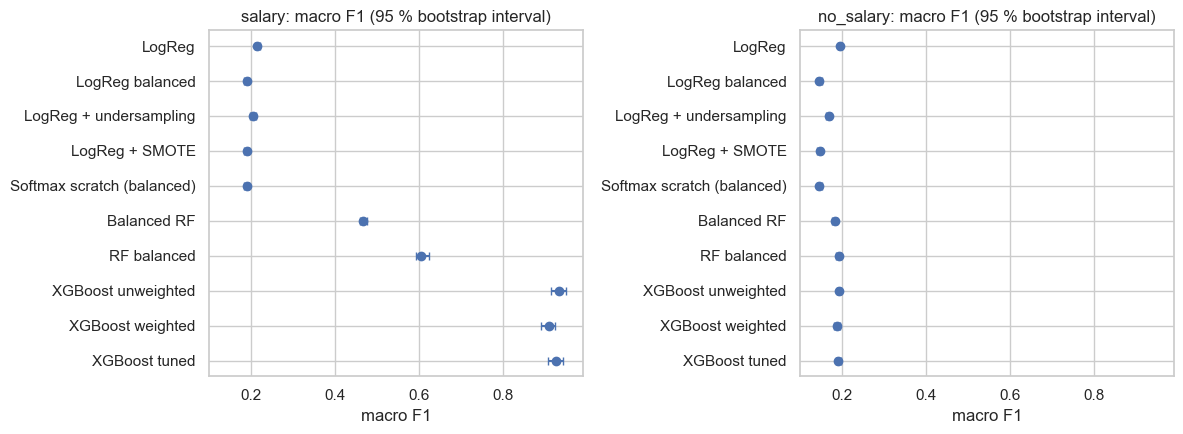

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, fs in zip(axes, data):
    r = results[results['features'] == fs].iloc[::-1]
    ax.errorbar(r['macro_f1'], range(len(r)),
                xerr=[r['macro_f1'] - r['macro_f1_low'], r['macro_f1_high'] - r['macro_f1']],
                fmt='o', capsize=3)
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r['model'])
    ax.set_title(f'{fs}: macro F1 (95 % bootstrap interval)'); ax.set_xlabel('macro F1')
plt.tight_layout()
plt.show()

## Recall per class

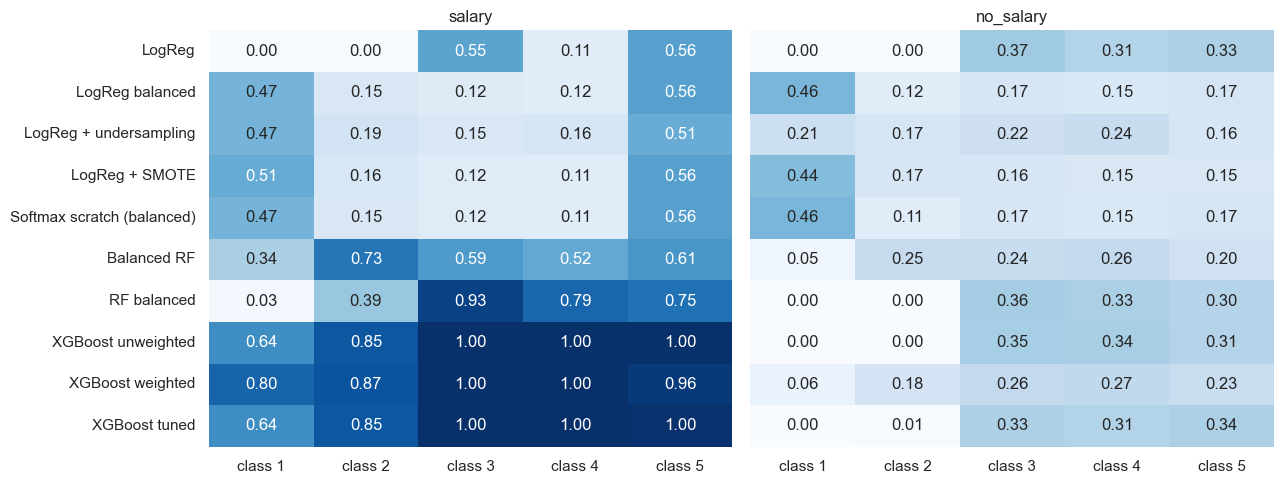

In [5]:
labels = [1, 2, 3, 4, 5]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, fs in zip(axes, data):
    rec = pd.DataFrame({name: evaluate(y_test, preds[(fs, name)])[1]['recall'] for name in MODELS}).T
    rec.columns = [f'class {c}' for c in labels]
    sns.heatmap(rec, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(fs)
plt.tight_layout()
plt.show()

## Are the differences real? Paired bootstrap

For two models, the difference of a metric is computed on the same resampled rows. If the interval contains 0, the data do not show a difference.

In [6]:
pairs = [('salary', 'XGBoost tuned', 'XGBoost weighted'),
         ('salary', 'XGBoost weighted', 'XGBoost unweighted'),
         ('salary', 'XGBoost tuned', 'LogReg balanced'),
         ('no_salary', 'XGBoost tuned', 'LogReg'),
         ('no_salary', 'LogReg', 'LogReg balanced')]
rows = []
for fs, a, b in pairs:
    d = bootstrap_diff(y_test, preds[(fs, a)], preds[(fs, b)])
    for m in ['macro_f1', 'recall_1']:
        v, lo, hi = d.loc[m]
        rows.append({'features': fs, 'A - B': f'{a} - {b}', 'metric': m, 'diff': v, 'low': lo, 'high': hi,
                     'distinguishable from 0': not (lo <= 0 <= hi)})
diffs = pd.DataFrame(rows)
diffs.set_index(['features', 'A - B', 'metric']).round(3)

diff    low   high  \
features  A - B                                 metric                          
salary    XGBoost tuned - XGBoost weighted      macro_f1  0.017 -0.001  0.035   
                                                recall_1 -0.163 -0.247 -0.088   
          XGBoost weighted - XGBoost unweighted macro_f1 -0.024 -0.043 -0.006   
                                                recall_1  0.163  0.088  0.247   
          XGBoost tuned - LogReg balanced       macro_f1  0.736  0.716  0.753   
                                                recall_1  0.162  0.083  0.241   
no_salary XGBoost tuned - LogReg                macro_f1 -0.003 -0.010  0.004   
                                                recall_1  0.000  0.000  0.000   
          LogReg - LogReg balanced              macro_f1  0.049  0.043  0.054   
                                                recall_1 -0.462 -0.571 -0.356   

                                                          distinguishable from 0  
features  A - B                                 metric                            
salary    XGBoost tuned - XGBoost weighted      macro_f1                   False  
                                                recall_1                    True  
          XGBoost weighted - XGBoost unweighted macro_f1                    True  
                                                recall_1                    True  
          XGBoost tuned - LogReg balanced       macro_f1                    True  
                                                recall_1                    True  
no_salary XGBoost tuned - LogReg                macro_f1                   False  
                                                recall_1                   False  
          LogReg - LogReg balanced              macro_f1                    True  
                                                recall_1                    True

## Feature importance (tuned XGBoost, salary set)

Gain-based importance: how much each feature improves the splits that use it.

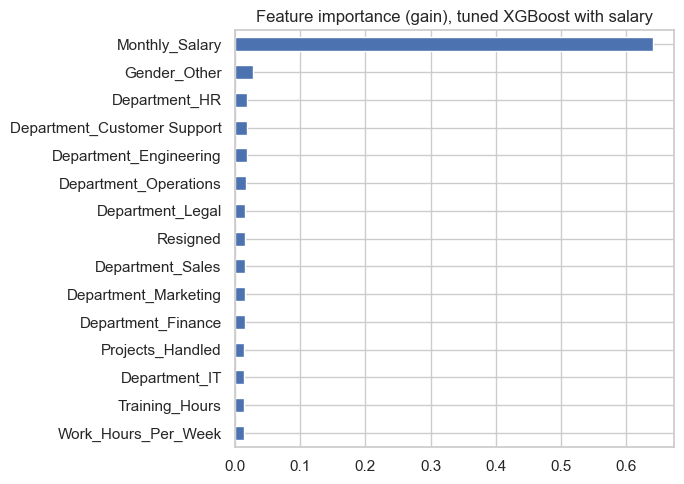

Monthly_Salary                 0.641
Gender_Other                   0.027
Department_HR                  0.019
Department_Customer Support    0.019
Department_Engineering         0.018
dtype: float32

In [7]:
X_tr = data['salary']['X_train']
xgb_tuned = WeightedXGB(**best_params, n_jobs=-1).fit(X_tr, y_train)
importance = pd.Series(xgb_tuned.model_.feature_importances_, index=X_tr.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
importance.head(15).iloc[::-1].plot.barh(ax=ax)
ax.set_title('Feature importance (gain), tuned XGBoost with salary')
plt.tight_layout()
plt.show()
importance.head(5).round(3)

## Export

Everything the README needs, in one file.

In [8]:
def clean(x):
    return float(x) if isinstance(x, (np.floating, np.integer)) else x

out = {
    'test_support': {int(k): int(v) for k, v in y_test.value_counts().sort_index().items()},
    'xgb_best_params': {k: clean(v) for k, v in best_params.items()},
    'models': [{k: clean(v) for k, v in r.items()} for r in results.to_dict('records')],
    'paired_differences': [{k: clean(v) if not isinstance(v, (bool, np.bool_)) else bool(v) for k, v in r.items()}
                           for r in diffs.to_dict('records')],
    'feature_importance_salary_set': {k: float(v) for k, v in importance.items()},
}
Path('../results/results.json').write_text(json.dumps(out, indent=2))
Path('../results/results.json').stat().st_size

16401

## Notes

**Ranking with salary (macro F1, 95% CI).** XGBoost unweighted 0.933 [0.914, 0.950], tuned 0.926 [0.907, 0.943], weighted 0.909 [0.890, 0.924]. Then RF balanced 0.606 and Balanced RF 0.467. Linear models stay at 0.19–0.22. The softmax from scratch matches sklearn's balanced LogReg (0.189 vs 0.190). XGBoost accuracy is 0.98, not 1.00, because job title is excluded and salary alone is ambiguous.

**Ranking without salary.** All models are at chance (0.146–0.195 macro F1). LogReg 0.195 [0.190, 0.200] and the tree models 0.192 are indistinguishable. Rebalancing lowers the score (0.146–0.147, CIs do not overlap with plain LogReg). Tuning brings nothing (0.192 → 0.192).

**Recall per class.**
- With salary, XGBoost unweighted gets 0.64 [0.53, 0.75] on class 1 and 1.00 on classes 3–5. Weighting raises class 1 to 0.80 [0.71, 0.89] but lowers macro F1 (0.933 → 0.909): a trade-off, not a gain. The class 1 intervals overlap and are about ±0.11 wide (80 test rows).
- Without salary, unweighted models have recall ≈ 0 on classes 1–2. Rebalanced models reach ~0.45 on class 1 and 0.11–0.17 elsewhere, because they simply predict class 1 more often.

**Feature importance.** `Monthly_Salary` carries 0.641 of the gain. All other features are at or below 0.027, a flat tail of noise.

**Paired differences.**
- Tuned vs weighted XGBoost (salary): XX [XX, XX].
- Weighted vs unweighted XGBoost (salary): XX [XX, XX].
- Tuned XGBoost vs LogReg (no salary): XX [XX, XX].

**Conclusion.** Everything predictable comes from `Monthly_Salary`, which is built from the score (leakage). Without it, no model beats the ~0.19 baseline and rebalancing only moves recall between classes.